# Proyecto BATSÚ — Notebook 06: Comparación de agentes (DQN, QR-DQN, PPO)

**Universidad Cenfotec — MISIA** · Alvaro Granados, Jose Leonel Hernández

Este notebook es una **extensión del alcance de la tesis** (Sección 5.7 y Capítulo 8), pensada como base de un artículo: compara sobre el mismo ambiente, la misma recompensa y el mismo protocolo de evaluación tres agentes de aprendizaje por refuerzo profundo, contra la heurística de referencia y la política aleatoria:

- **DQN** (Stable-Baselines3): la línea base de la tesis; estima el valor esperado Q(s, a). Off-policy, buffer precargado con el corpus.
- **QR-DQN** (sb3-contrib): variante distribucional que estima la distribución de retornos mediante cuantiles en lugar de su media; pertinente porque los desenlaces del simulador son estocásticos por diseño. Off-policy, buffer precargado.
- **PPO** (Stable-Baselines3): gradiente de política con región de confianza, la evolución que recomienda el tutor para diálogos. On-policy: no usa el buffer, aprende interactuando con el simulador. Esta asimetría es inherente a los algoritmos y se declara.

Todos usan la misma red (dos capas de 64), el mismo presupuesto máximo de pasos y el mismo criterio de parada. Los tres se evalúan sobre los mismos 300 episodios. PPO va aquí con el estado plano de 20 dimensiones; el grafo de isócronas queda para una segunda etapa.

**Secciones**
1. Configuración
2. Parámetros
3. Corpus, manifiesto y ambiente
4. Modelo de recompensa (si hay juez)
5. Entrenamiento de los tres agentes con el mismo criterio de parada
6. Tabla comparativa y curvas
7. Guardado de resultados


## 1. Configuración

CPU basta. Se instala `stable-baselines3`, que trae la implementación de referencia de DQN (Raffin et al., 2021; Tabla 5.2).


In [1]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import sys, json, time
from datetime import datetime, timezone
import jupyter_client.session as _jcs
_jcs.utcnow = lambda: datetime.now(timezone.utc)   # sustituye la función obsoleta del propio Jupyter que genera el aviso de utcnow(); no interviene en los cálculos
import numpy as np
import pandas as pd

NOMBRE_CARPETA = 'DatosBatsuv2'
candidatos = [p for p in Path('/content/drive/MyDrive').rglob(NOMBRE_CARPETA) if p.is_dir()]
assert candidatos, f'No se encontró la carpeta "{NOMBRE_CARPETA}"'
BASE_DIR = candidatos[0]
CORPUS_DIR = BASE_DIR / 'corpus'
RESULTADOS_DIR = BASE_DIR / 'resultados'
RESULTADOS_DIR.mkdir(exist_ok=True)
sys.path.insert(0, str(BASE_DIR))

!pip install -q gymnasium stable-baselines3 sb3-contrib pyarrow 2>&1 | tail -1
import torch, gymnasium as gym, stable_baselines3 as sb3
import matplotlib.pyplot as plt
print('torch', torch.__version__, '· SB3', sb3.__version__, '· gymnasium', gym.__version__)


Mounted at /content/drive
torch 2.11.0+cpu · SB3 2.9.2 · gymnasium 1.4.0


Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.


## 2. Parámetros

- **`ETIQUETA_CORPUS`**, **`USAR_JUEZ`**, **`SEMILLA`**: igual que en el notebook 05.
- **Hiperparámetros por agente**: DQN y QR-DQN comparten todo salvo los 50 cuantiles de QR-DQN; PPO usa los valores por defecto de Stable-Baselines3 con la misma red y el mismo γ. No se hace búsqueda de hiperparámetros: la comparación es entre algoritmos con configuraciones estándar, y así se declara.
- **Criterio de parada común**: evaluación cada `EVAL_CADA` pasos sobre `N_EVAL_EPISODIOS` fijos; parada tras `PACIENCIA` evaluaciones sin mejora, o en `MAX_PASOS`. Para PPO, la evaluación ocurre al cierre del *rollout* que cruza el múltiplo de `EVAL_CADA`.


In [2]:
ETIQUETA_CORPUS = 'v0_escala05_prior40'
USAR_JUEZ = 'auto'             # 'auto' | 'proxy'
CLAVE_ALEATORIA = 20260925     # clave de reproducibilidad (random seed); no confundir con las 60 semillas de turista
RED = dict(net_arch=[64, 64])

HIPER = {
    'DQN':    dict(learning_rate=5e-4, buffer_size=300_000, learning_starts=0, batch_size=128, gamma=0.95, train_freq=4, gradient_steps=1,
                   target_update_interval=1_000, exploration_fraction=0.30, exploration_initial_eps=1.0, exploration_final_eps=0.05, policy_kwargs=RED),
    'QR-DQN': dict(learning_rate=5e-4, buffer_size=300_000, learning_starts=0, batch_size=128, gamma=0.95, train_freq=4, gradient_steps=1,
                   target_update_interval=1_000, exploration_fraction=0.30, exploration_initial_eps=1.0, exploration_final_eps=0.05,
                   policy_kwargs=dict(net_arch=[64, 64], n_quantiles=50)),
    'PPO':    dict(learning_rate=3e-4, n_steps=2_048, batch_size=128, n_epochs=10, gamma=0.95, gae_lambda=0.95, clip_range=0.2, ent_coef=0.01, policy_kwargs=RED),
}

# Criterio de parada y protocolo de evaluación comunes (Sección 3.5), idénticos al notebook 05
MAX_PASOS = 200_000
EVAL_CADA = 10_000
N_SEL_EPISODIOS = 300         # conjunto de selección: decide la parada y el mejor modelo
N_TEST_EPISODIOS = 600        # conjunto de prueba independiente: solo para la tabla final
PACIENCIA = 5
CLAVES_REPLICAS = [CLAVE_ALEATORIA + i for i in range(5)]   # 5 réplicas por algoritmo

RUTA_CORPUS = CORPUS_DIR / f'corpus_{ETIQUETA_CORPUS}.parquet'
RUTA_MANIF = CORPUS_DIR / f'manifiesto_{ETIQUETA_CORPUS}.json'
assert RUTA_CORPUS.exists() and RUTA_MANIF.exists(), 'Falta el corpus o su manifiesto (notebook 02)'
print('Corpus:', RUTA_CORPUS.name, '· agentes:', list(HIPER), '· réplicas por agente:', len(CLAVES_REPLICAS))


Corpus: corpus_v0_escala05_prior40.parquet · agentes: ['DQN', 'QR-DQN', 'PPO'] · réplicas por agente: 5


## 3. Corpus, manifiesto y ambiente

Se carga el corpus y su manifiesto, se aplican al simulador los parámetros con los que se generó (escala de cierre y prior), y se determina si hay juez. Se construye el ambiente de entrenamiento y el conjunto fijo de episodios de evaluación: cada política se evaluará con las mismas 300 combinaciones (semilla, generador aleatorio), de modo que las diferencias entre políticas no se deban al azar del turista simulado.


In [3]:
import batsu_sim as bs
corpus = pd.read_parquet(RUTA_CORPUS)
manif = json.load(open(RUTA_MANIF, encoding='utf-8'))
bs.ESCALA_P_CIERRE = manif['parametros']['escala_p_cierre']
bs.PRIOR_PUNTOS = manif['parametros']['prior_puntos']

hay_juez = manif.get('juez', {}).get('completado', False) or ('r_juez' in corpus and (corpus['r_juez'] != 0).any())
modo_juez = 'modelo' if (USAR_JUEZ == 'auto' and hay_juez) else 'proxy'
COLS_S = [c for c in corpus.columns if c.startswith('s_')]
COLS_SP = [c for c in corpus.columns if c.startswith('sp_')]
n_ep = corpus.groupby(['id_semilla', 'corrida']).ngroups
print(f'Corpus: {len(corpus):,} transiciones · {n_ep:,} episodios · escala {bs.ESCALA_P_CIERRE} · prior {bs.PRIOR_PUNTOS} · '
      f'juez en corpus: {"sí" if hay_juez else "no"} → modo de recompensa: {modo_juez}')

# Conjuntos fijos de evaluación: (id_semilla, semilla_rng), idénticos a los del notebook 05 (mismas claves)
ids = list(bs.semillas['id'])
rng_sel = np.random.default_rng(CLAVE_ALEATORIA + 1)
SEL_SET = [(ids[i % 60], int(rng_sel.integers(1e9))) for i in range(N_SEL_EPISODIOS)]
rng_test = np.random.default_rng(CLAVE_ALEATORIA + 2)
TEST_SET = [(ids[i % 60], int(rng_test.integers(1e9))) for i in range(N_TEST_EPISODIOS)]
assert not set(SEL_SET) & set(TEST_SET), 'selección y prueba comparten episodios'
print(f'Conjunto de selección: {len(SEL_SET)} episodios · conjunto de prueba: {len(TEST_SET)} episodios · sin solapamiento')

def evaluar(politica, env, conjunto, mascara=False):
    """Evalúa una política (función env -> acción) sobre un conjunto fijo. Devuelve métricas del objetivo 6
    y la lista de retornos por episodio (clave '_retornos') para los intervalos de confianza."""
    rets, longs, des, viol = [], [], [], 0
    for sid, seed in conjunto:
        obs, _ = env.reset(seed=seed, options={'id': sid})
        ret = 0.0
        while True:
            a = politica(env.unwrapped, obs)
            if mascara:
                m = env.unwrapped.mascara_acciones()
                if not m[a]:
                    a = 0 if m[0] else int(np.flatnonzero(m)[0])
            obs, r, term, trunc, info = env.step(a)
            ret += r; viol += int(info['violacion_trust_gate'])
            if term or trunc:
                break
        rets.append(ret); longs.append(info['turno']); des.append(info['desenlace'])
    d = pd.Series(des).value_counts(normalize=True)
    return {'retorno': float(np.mean(rets)), 'turnos': float(np.mean(longs)), 'conversion': float(d.get('conversion', 0)),
            'inviable': float(d.get('recomendacion_inviable', 0)), 'negativos': float(d.get('rechazo', 0) + d.get('abandono', 0) + d.get('recomendacion_inviable', 0)),
            'violaciones_por_ep': viol / len(conjunto), '_retornos': rets}


Parámetros cargados. Acciones: 7 | Estados afectivos: 5
Semillas: 60 OK · distancia máxima 267.1 km · inviables: ['CR-TUR-005', 'CR-TUR-020', 'CR-TUR-035', 'CR-TUR-044', 'CR-TUR-054']
Tabla de reacción: 35 celdas OK
Modificadores: 7 OK
Dinámica OK. Desenlaces al cerrar (entusiasmado, oferta baja, prior=conversión):
{'conversion': 0.82, 'avance_parcial': 0.144, 'abandono': 0.036} | esperado: conv (75+40)/140=0.82, avance 0.14, abandono 0.04
Ambiente creado · Box(0.0, 1.0, (21,), float32) · Discrete(7)
Máscara Trust Gate para CR-TUR-001 (presupuesto bajo, solo texto): {'solicitar_informacion': True, 'ofrecer_paquete_bajo': True, 'ofrecer_paquete_medio': False, 'ofrecer_paquete_alto': False, 'enviar_activo': False, 'escalar_humano': True, 'cerrar_conversacion': True}
Corpus: 26,343 transiciones · 6,000 episodios · escala 0.5 · prior 40 · juez en corpus: sí → modo de recompensa: modelo
Conjunto de selección: 300 episodios · conjunto de prueba: 600 episodios · sin solapamiento


## 4. Modelo de recompensa (si hay juez)

Cuando el corpus tiene `r_juez`, se entrena un regresor que lo predice a partir de la transición: el vector de estado s (20), la acción en one-hot (7) y el vector s' (20), 47 entradas en total. Es una red de dos capas de 64 unidades entrenada con error cuadrático, con partición de validación **por episodio** (no por turno), para que la métrica no esté inflada por turnos vecinos del mismo diálogo. Se reporta el error absoluto medio y el R² en validación, que es la calidad del modelo de recompensa que la Sección 5.5 exige reportar junto con los resultados de convergencia.

El modelo se usa después dentro de un *wrapper* del ambiente que suma `r_juez` predicho a la recompensa de cada paso. Si el corpus no tiene juez, esta sección se salta y `r_juez = 0`.


In [4]:
import torch.nn as nn

modelo_recompensa = None
if modo_juez == 'modelo':
    ruta_modelo = RESULTADOS_DIR / f'modelo_recompensa_{ETIQUETA_CORPUS}.pt'
    assert ruta_modelo.exists(), 'No existe el modelo de recompensa: correr primero el notebook 05'
    # Misma partición por episodio que el notebook 05 (misma clave aleatoria), solo para verificar
    juzg = corpus.copy()
    A = np.eye(len(bs.ACCIONES), dtype=np.float32)[juzg['accion'].values]
    X = np.hstack([juzg[COLS_S].values.astype(np.float32), A, juzg[COLS_SP].values.astype(np.float32)])
    y = juzg['r_juez'].values.astype(np.float32)
    ep_id = (juzg['id_semilla'] + '-' + juzg['corrida'].astype(str)).values
    eps_unicos = np.unique(ep_id); rng = np.random.default_rng(CLAVE_ALEATORIA)
    val_eps = set(rng.choice(eps_unicos, size=int(0.2 * len(eps_unicos)), replace=False))
    mval = np.array([e in val_eps for e in ep_id])
    Xv, yv = torch.tensor(X[mval]), y[mval]

    modelo_recompensa = nn.Sequential(nn.Linear(X.shape[1], 64), nn.ReLU(), nn.Linear(64, 64), nn.ReLU(), nn.Linear(64, 1))
    modelo_recompensa.load_state_dict(torch.load(ruta_modelo)); modelo_recompensa.eval()
    with torch.no_grad():
        pv = modelo_recompensa(Xv).squeeze(1).numpy()
    mse = float(np.mean((pv - yv)**2)); mae = float(np.mean(np.abs(pv - yv)))
    r2 = 1 - float(np.sum((pv - yv)**2) / np.sum((yv - yv.mean())**2))
    print(f'Modelo de recompensa cargado de {ruta_modelo.name} · entradas: {X.shape[1]}')
    print(f'Verificación en validación ({len(val_eps)} episodios, {mval.sum():,} transiciones): MSE = {mse:.4f} · MAE = {mae:.3f} · R² = {r2:.3f}  (notebook 05: 0.0720 / 0.198 / 0.174)')
else:
    print('Sin juez en el corpus: se entrena con recompensa proxy (r_juez = 0)')

Modelo de recompensa cargado de modelo_recompensa_v0_escala05_prior40.pt · entradas: 49
Verificación en validación (1200 episodios, 5,162 transiciones): MSE = 0.0720 · MAE = 0.198 · R² = 0.174  (notebook 05: 0.0720 / 0.198 / 0.174)


## 5. Entrenamiento de los tres agentes con el mismo criterio de parada

Se define una función de entrenamiento única: crea el agente, precarga el buffer si es off-policy (DQN, QR-DQN), entrena hasta `MAX_PASOS` con el *callback* de parada por convergencia (el mismo del notebook 05) y devuelve el mejor modelo, el historial de evaluaciones y los pasos hasta el mejor. Los tres agentes se entrenan en secuencia con la misma semilla.


In [5]:
from stable_baselines3 import DQN, PPO
from sb3_contrib import QRDQN
from stable_baselines3.common.monitor import Monitor
from stable_baselines3.common.callbacks import BaseCallback

class EnvConRecompensaModelo(gym.Wrapper):
    """Suma al reward la predicción del modelo de recompensa (sustituto del juez, Sección 5.5)."""
    def __init__(self, env, modelo):
        super().__init__(env); self.modelo = modelo; self._obs = None
    def reset(self, **kw):
        self._obs, info = self.env.reset(**kw); return self._obs, info
    def step(self, a):
        obs2, r, term, trunc, info = self.env.step(a)
        if self.modelo is not None:
            x = np.concatenate([self._obs, np.eye(len(bs.ACCIONES), dtype=np.float32)[int(a)], obs2]).astype(np.float32)
            with torch.no_grad():
                rj = float(self.modelo(torch.tensor(x)[None]).item())
            r += rj; info['r_juez'] = rj
        self._obs = obs2
        return obs2, r, term, trunc, info

def hacer_env():
    e = bs.BatsuEnv(bs.semillas)
    return EnvConRecompensaModelo(e, modelo_recompensa) if modo_juez == 'modelo' else e

env_eval = hacer_env()

class ParadaPorConvergencia(BaseCallback):
    """Evalúa sobre el conjunto de SELECCIÓN al cruzar cada múltiplo de EVAL_CADA (PPO evalúa al cierre del rollout);
    guarda el mejor modelo; detiene tras PACIENCIA evaluaciones sin mejora."""
    def __init__(self, nombre, ruta_modelo):
        super().__init__(); self.nombre = nombre; self.ruta = ruta_modelo; self.historial = []
        self.mejor = -np.inf; self.sin_mejora = 0; self.mejor_paso = 0; self.t0 = time.time(); self.siguiente_eval = EVAL_CADA
    def _on_step(self):
        if self.num_timesteps < self.siguiente_eval:
            return True
        self.siguiente_eval += EVAL_CADA
        pol = lambda env, obs: int(self.model.predict(obs, deterministic=True)[0])
        m = evaluar(pol, env_eval, SEL_SET); m.pop('_retornos')
        m.update(paso=self.num_timesteps, td_loss=float(self.model.logger.name_to_value.get('train/loss', np.nan)),
                 minutos=(time.time() - self.t0) / 60)
        self.historial.append(m)
        mejora = m['retorno'] > self.mejor + 1e-6
        print(f"    paso {m['paso']:>7,} · retorno {m['retorno']:6.2f} · conv {m['conversion']:.2f} · inviable {m['inviable']:.2f} · "
              f"viol/ep {m['violaciones_por_ep']:.2f}{'  ← mejor' if mejora else ''}")
        if mejora:
            self.mejor, self.sin_mejora, self.mejor_paso = m['retorno'], 0, m['paso']
            self.model.save(self.ruta)
        else:
            self.sin_mejora += 1
            if self.sin_mejora >= PACIENCIA:
                print(f'    Criterio de parada: {PACIENCIA} evaluaciones sin mejora. Mejor retorno {self.mejor:.2f} en el paso {self.mejor_paso:,}.')
                return False
        return True

# Transiciones del corpus para el buffer de los agentes off-policy
r_col = corpus['reward'] if modo_juez == 'modelo' else (corpus['r_shaping'] + corpus['r_trust'] + corpus['r_terminal'])
S, SP = corpus[COLS_S].values.astype(np.float32), corpus[COLS_SP].values.astype(np.float32)
A_CORPUS, R_CORPUS = corpus['accion'].values, r_col.values.astype(np.float32)
TERM, TRUNC = corpus['terminated'].values.astype(bool), corpus['truncated'].values.astype(bool)

def precargar(agente):
    for i in range(len(corpus)):
        agente.replay_buffer.add(S[i:i+1], SP[i:i+1], np.array([A_CORPUS[i]]), np.array([R_CORPUS[i]], dtype=np.float32),
                                 np.array([TERM[i]]), [{'TimeLimit.truncated': bool(TRUNC[i])}])

CLASES = {'DQN': DQN, 'QR-DQN': QRDQN, 'PPO': PPO}

def entrenar(nombre, clave, i):
    torch.manual_seed(clave); np.random.seed(clave)
    env_train = Monitor(hacer_env())
    agente = CLASES[nombre]('MlpPolicy', env_train, seed=clave, verbose=0, **HIPER[nombre])
    if nombre != 'PPO':
        precargar(agente)
    ruta = RESULTADOS_DIR / f'{nombre}_{ETIQUETA_CORPUS}_{modo_juez}_r{i}'
    cb = ParadaPorConvergencia(nombre, ruta)
    agente.learn(total_timesteps=MAX_PASOS, callback=cb, log_interval=None)
    pasos = int(agente.num_timesteps)
    agente = CLASES[nombre].load(ruta, env=env_train)
    print(f'  {nombre} réplica {i}: {pasos:,} pasos · {(time.time()-cb.t0)/60:.1f} min · mejor modelo del paso {cb.mejor_paso:,} '
          f'(retorno en selección {cb.mejor:.2f})')
    return agente, {'algoritmo': nombre, 'replica': i, 'clave': clave, 'hist': pd.DataFrame(cb.historial), 'pasos': pasos,
                    'mejor_paso': int(cb.mejor_paso), 'mejor_sel': float(cb.mejor), 'ruta': ruta.name, 'minutos': (time.time() - cb.t0) / 60}

#agentes, replicas = {}, {}
#t_total = time.time()
#for nombre in HIPER:
#    print(f'\n=== {nombre} · {"buffer precargado con el corpus" if nombre != "PPO" else "on-policy, sin buffer precargado"} ===')
#    for i, clave in enumerate(CLAVES_REPLICAS, 1):
#        print(f'  Réplica {i}/{len(CLAVES_REPLICAS)} (clave aleatoria {clave})')
#        agentes[(nombre, i)], replicas[(nombre, i)] = entrenar(nombre, clave, i)

#print(f'\n{len(replicas)} entrenamientos en {(time.time()-t_total)/60:.1f} min')

# Carga de la corrida guardada (sin reentrenar): modelos, historial y registro de la sección 7
agentes, replicas = {}, {}
sufijo = f'agentes_{ETIQUETA_CORPUS}_{modo_juez}'
registro_previo = json.load(open(RESULTADOS_DIR / f'registro_{sufijo}.json', encoding='utf-8'))
hist_previo = pd.read_csv(RESULTADOS_DIR / f'entrenamiento_{sufijo}.csv')
for r in registro_previo['replicas']:
    nombre, i = r['algoritmo'], r['replica']
    agentes[(nombre, i)] = CLASES[nombre].load(RESULTADOS_DIR / r['modelo'], env=Monitor(hacer_env()))
    h = hist_previo[(hist_previo['algoritmo'] == nombre) & (hist_previo['replica'] == i)].drop(columns=['algoritmo', 'replica'])
    replicas[(nombre, i)] = {'algoritmo': nombre, 'replica': i, 'clave': r['clave'], 'hist': h.reset_index(drop=True),
                             'pasos': r['pasos'], 'mejor_paso': r['mejor_paso'], 'mejor_sel': r['retorno_seleccion'],
                             'ruta': r['modelo'], 'minutos': r['minutos']}
print(f"{len(replicas)} modelos cargados · entrenados el {registro_previo['fecha']} en {registro_previo['hardware']['cpu']}")


15 modelos cargados · entrenados el 2026-10-14 19:27:23 en Intel(R) Xeon(R) CPU @ 2.20GHz


## 6. Tabla comparativa y curvas

Las cinco políticas se evalúan con el mismo protocolo (mismos 300 episodios, política determinista): aleatoria, heurística de referencia y los tres agentes con su mejor modelo. Se añade una columna con los pasos de entrenamiento hasta el mejor modelo, que es la medida de eficiencia de muestra.

Se grafican las curvas de aprendizaje superpuestas (retorno de evaluación por paso), con la heurística como línea de referencia, y la distribución de desenlaces por política.


Evaluación sobre el conjunto de prueba (600 episodios). IC95 del retorno: sobre episodios para las referencias, sobre las 5 réplicas para los agentes.

                         retorno  retorno_ic95  turnos  conversion  inviable  negativos  violaciones_por_ep  pasos_hasta_mejor  minutos
Aleatoria                  0.089         0.513   3.248       0.220     0.052      0.517               0.515                NaN      NaN
Heurística (referencia)    7.532         0.519   4.328       0.585     0.065      0.142               0.080                NaN      NaN
DQN                        8.446         0.136   4.643       0.606     0.000      0.107               0.000            84000.0     3.34
QR-DQN                     8.448         0.094   5.135       0.584     0.000      0.070               0.000            58000.0     6.72
PPO                        8.357         0.051   5.000       0.583     0.001      0.073               0.002           156000.0     4.82

Por réplica (prueba):
algoritmo

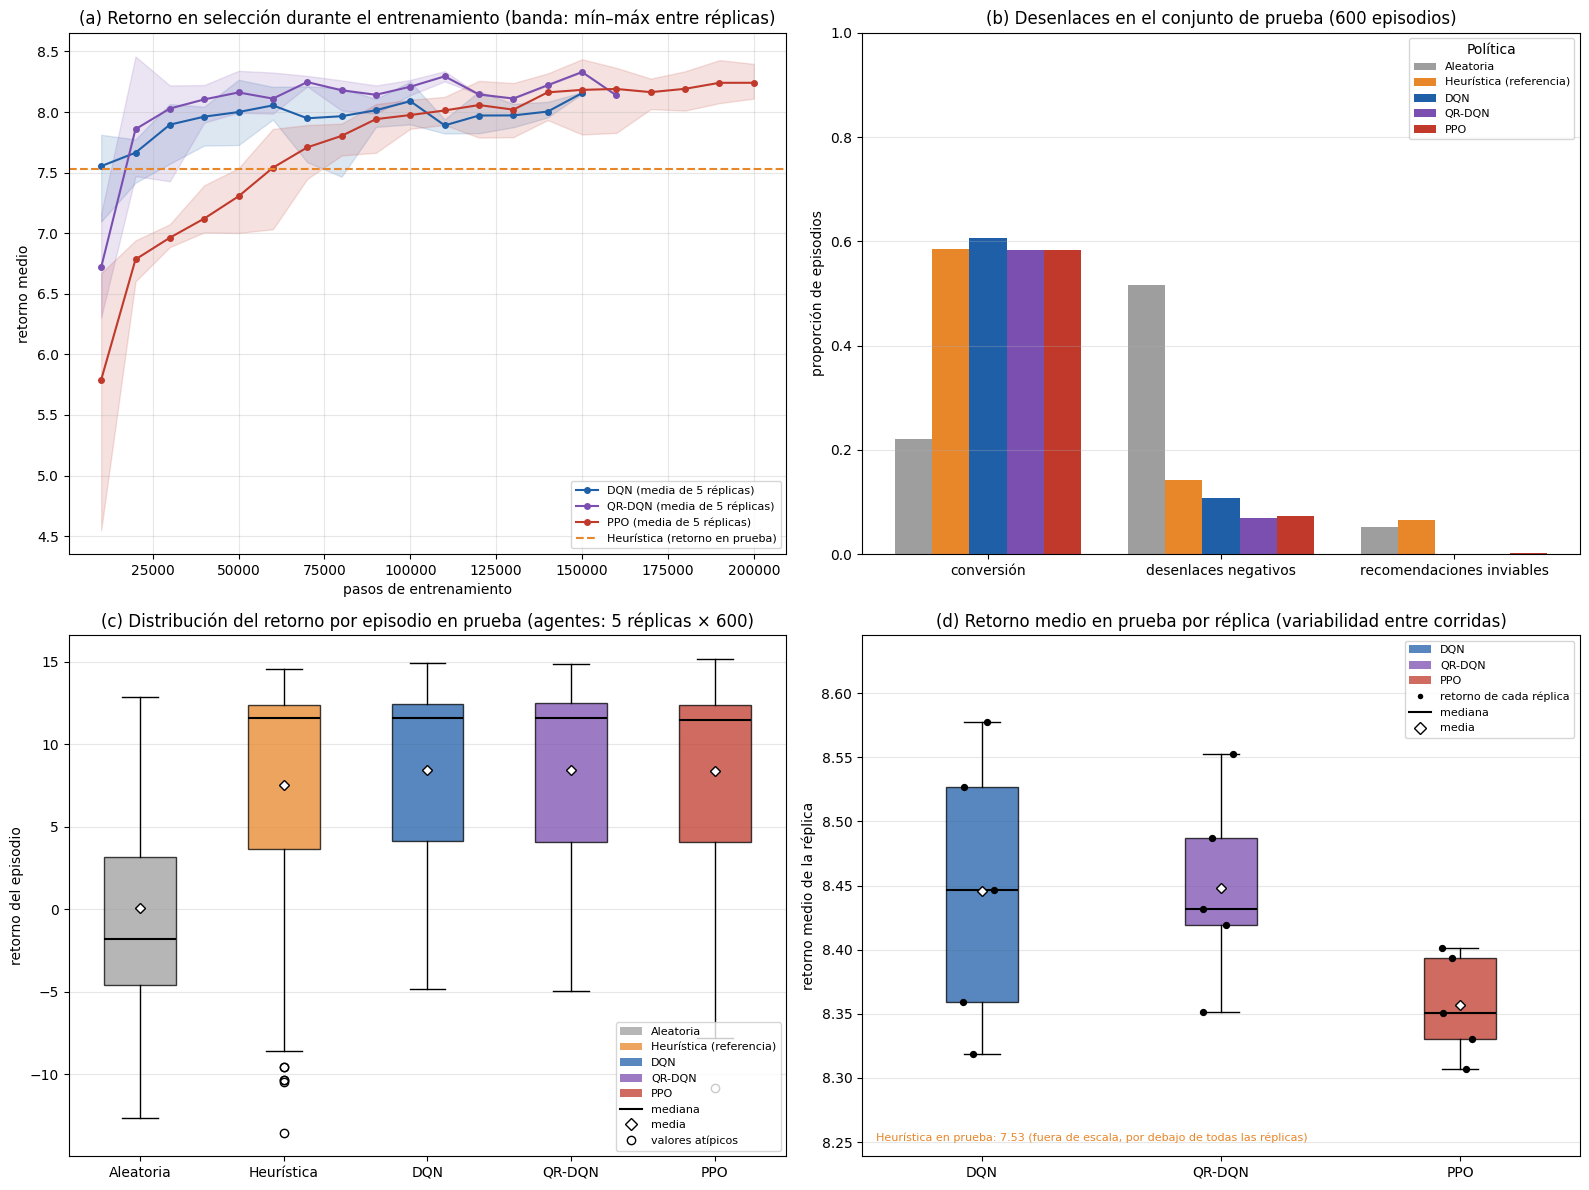

Figuras guardadas en resultados


In [6]:
from scipy.stats import t as t_student, ttest_rel, wilcoxon
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

pol_heur = lambda env, obs: bs.politica_heuristica(env, 0.0)
pol_rand = lambda env, obs: bs.politica_aleatoria(env)
METRICAS = ['retorno', 'turnos', 'conversion', 'inviable', 'negativos', 'violaciones_por_ep']
ALGOS = list(HIPER)
COLOR = {'Aleatoria': '#9e9e9e', 'Heurística (referencia)': '#e8862a', 'DQN': '#1f5fa8', 'QR-DQN': '#7b4fb0', 'PPO': '#c0392b'}

def ic95(x):
    x = np.asarray(x, dtype=float); n = len(x)
    return float(x.mean()), (float(t_student.ppf(0.975, n - 1) * x.std(ddof=1) / np.sqrt(n)) if n > 1 else 0.0)

# 1) Referencias sobre el conjunto de PRUEBA
filas, ic, retornos = {}, {}, {}
for nombre, pol in [('Aleatoria', pol_rand), ('Heurística (referencia)', pol_heur)]:
    m = evaluar(pol, env_eval, TEST_SET); rets = m.pop('_retornos')
    filas[nombre] = m; ic[nombre] = ic95(rets)[1]; retornos[nombre] = rets

# 2) Cada algoritmo × réplica sobre el conjunto de PRUEBA
por_replica, ret_ep = [], {}          # ret_ep[algo] = matriz réplicas × episodios
for (nombre, i), ag in agentes.items():
    pol = lambda env, obs, ag=ag: int(ag.predict(obs, deterministic=True)[0])
    m = evaluar(pol, env_eval, TEST_SET); rets = m.pop('_retornos')
    ret_ep.setdefault(nombre, []).append(rets); retornos.setdefault(nombre, []).extend(rets)
    r = replicas[(nombre, i)]
    por_replica.append({'algoritmo': nombre, 'replica': i, **m, 'retorno_seleccion': r['mejor_sel'],
                        'pasos_hasta_mejor': r['mejor_paso'], 'pasos_totales': r['pasos'], 'minutos': round(r['minutos'], 1)})
por_replica = pd.DataFrame(por_replica)
for nombre in ALGOS:
    sub = por_replica[por_replica['algoritmo'] == nombre]
    filas[nombre] = {**sub[METRICAS].mean().to_dict(), 'pasos_hasta_mejor': sub['pasos_hasta_mejor'].mean(), 'minutos': sub['minutos'].mean()}
    ic[nombre] = ic95(sub['retorno'])[1]

comparacion = pd.DataFrame(filas).T[METRICAS + ['pasos_hasta_mejor', 'minutos']].round(3)
comparacion.insert(1, 'retorno_ic95', pd.Series(ic).round(3))
print(f'Evaluación sobre el conjunto de prueba ({len(TEST_SET)} episodios). IC95 del retorno: sobre episodios para las referencias, '
      f'sobre las {len(CLAVES_REPLICAS)} réplicas para los agentes.\n')
print(comparacion.to_string())
print('\nPor réplica (prueba):')
print(por_replica[['algoritmo', 'replica', 'retorno', 'conversion', 'inviable', 'violaciones_por_ep', 'retorno_seleccion', 'pasos_hasta_mejor', 'minutos']]
      .round(3).to_string(index=False))

# 3) Comparaciones pareadas por episodio (media de las réplicas en cada episodio)
medias_ep = {a: np.array(ret_ep[a]).mean(axis=0) for a in ALGOS}
heur = np.array(retornos['Heurística (referencia)'])
print('\nComparaciones pareadas por episodio (n = %d):' % len(TEST_SET))
for a in ALGOS:
    dif = medias_ep[a] - heur; md, hd = ic95(dif); _, p = wilcoxon(medias_ep[a], heur)
    print(f'  {a:7s} − heurística: {md:+.3f} ± {hd:.3f} · Wilcoxon p = {p:.2g} · supera en {np.mean(dif > 0):.1%} de los episodios')
for a in [x for x in ALGOS if x != 'DQN']:
    dif = medias_ep[a] - medias_ep['DQN']; md, hd = ic95(dif); _, p = wilcoxon(medias_ep[a], medias_ep['DQN'])
    print(f'  {a:7s} − DQN:        {md:+.3f} ± {hd:.3f} · Wilcoxon p = {p:.2g}')

# 4) Figuras (un color por política; cada panel se explica por sí solo)
hist = pd.concat([r['hist'].assign(algoritmo=r['algoritmo'], replica=r['replica']) for r in replicas.values()], ignore_index=True)

def panel_a(ax):
    for a in ALGOS:
        g = hist[hist['algoritmo'] == a].groupby('paso')['retorno'].agg(['mean', 'min', 'max'])
        ax.plot(g.index, g['mean'], marker='o', ms=4, color=COLOR[a], label=f'{a} (media de {len(CLAVES_REPLICAS)} réplicas)')
        ax.fill_between(g.index, g['min'], g['max'], color=COLOR[a], alpha=0.15)
    ax.axhline(comparacion.loc['Heurística (referencia)', 'retorno'], ls='--', color=COLOR['Heurística (referencia)'], label='Heurística (retorno en prueba)')
    ax.set_title('(a) Retorno en selección durante el entrenamiento (banda: mín–máx entre réplicas)')
    ax.set_xlabel('pasos de entrenamiento'); ax.set_ylabel('retorno medio'); ax.legend(fontsize=8); ax.grid(alpha=0.3)

def panel_b(ax):
    politicas = list(comparacion.index); metricas = ['conversion', 'negativos', 'inviable']; x = np.arange(len(metricas)); ancho = 0.16
    for j, p in enumerate(politicas):
        ax.bar(x + (j - 2) * ancho, comparacion.loc[p, metricas], ancho, color=COLOR[p], label=p)
    ax.set_xticks(x); ax.set_xticklabels(['conversión', 'desenlaces negativos', 'recomendaciones inviables']); ax.set_ylim(0, 1)
    ax.set_title('(b) Desenlaces en el conjunto de prueba (600 episodios)'); ax.set_ylabel('proporción de episodios')
    ax.legend(title='Política', fontsize=8); ax.grid(axis='y', alpha=0.3)

def panel_c(ax):
    politicas = list(comparacion.index)
    bp = ax.boxplot([retornos[p] for p in politicas], tick_labels=['Aleatoria', 'Heurística', 'DQN', 'QR-DQN', 'PPO'], patch_artist=True,
                    showmeans=True, medianprops=dict(color='black', lw=1.5), meanprops=dict(marker='D', markerfacecolor='white', markeredgecolor='black', ms=5))
    for caja, p in zip(bp['boxes'], politicas):
        caja.set_facecolor(COLOR[p]); caja.set_alpha(0.75)
    ley = [Patch(facecolor=COLOR[p], alpha=0.75, label=p) for p in politicas] + \
          [Line2D([0], [0], color='black', lw=1.5, label='mediana'), Line2D([0], [0], marker='D', color='w', markerfacecolor='white', markeredgecolor='black', ms=6, label='media'),
           Line2D([0], [0], marker='o', color='w', markerfacecolor='none', markeredgecolor='black', ms=6, label='valores atípicos')]
    ax.legend(handles=ley, fontsize=8, loc='lower right')
    ax.set_title('(c) Distribución del retorno por episodio en prueba (agentes: 5 réplicas × 600)'); ax.set_ylabel('retorno del episodio'); ax.grid(axis='y', alpha=0.3)

def panel_d(ax):
    datos = [por_replica.loc[por_replica['algoritmo'] == a, 'retorno'].values for a in ALGOS]
    bp = ax.boxplot(datos, tick_labels=ALGOS, patch_artist=True, showmeans=True, medianprops=dict(color='black', lw=1.5),
                    meanprops=dict(marker='D', markerfacecolor='white', markeredgecolor='black', ms=5))
    for caja, a in zip(bp['boxes'], ALGOS):
        caja.set_facecolor(COLOR[a]); caja.set_alpha(0.75)
    for k, d in enumerate(datos, 1):
        ax.scatter(np.full(len(d), k) + np.random.default_rng(0).uniform(-0.08, 0.08, len(d)), d, color='black', s=18, zorder=3)
    todo = np.concatenate(datos); margen = (todo.max() - todo.min()) * 0.25
    ax.set_ylim(todo.min() - margen, todo.max() + margen)
    h = comparacion.loc['Heurística (referencia)', 'retorno']
    ax.text(0.02, 0.03, f'Heurística en prueba: {h:.2f} (fuera de escala, por debajo de todas las réplicas)',
            transform=ax.transAxes, fontsize=8, color=COLOR['Heurística (referencia)'])
    ley = [Patch(facecolor=COLOR[a], alpha=0.75, label=a) for a in ALGOS] + \
          [Line2D([0], [0], marker='o', color='w', markerfacecolor='black', ms=5, label='retorno de cada réplica'),
           Line2D([0], [0], color='black', lw=1.5, label='mediana'),
           Line2D([0], [0], marker='D', color='w', markerfacecolor='white', markeredgecolor='black', ms=6, label='media')]
    ax.legend(handles=ley, fontsize=8, loc='upper right')
    ax.set_title('(d) Retorno medio en prueba por réplica (variabilidad entre corridas)'); ax.set_ylabel('retorno medio de la réplica'); ax.grid(axis='y', alpha=0.3)

fig, ax = plt.subplots(2, 2, figsize=(16, 12)); ax = ax.ravel()
panel_a(ax[0]); panel_b(ax[1]); panel_c(ax[2]); panel_d(ax[3])
plt.tight_layout(); plt.savefig(RESULTADOS_DIR / f'comparacion_agentes_{ETIQUETA_CORPUS}_{modo_juez}.png', dpi=150); plt.show()
for nombre, fn in [('a_aprendizaje', panel_a), ('b_desenlaces', panel_b), ('c_boxplot_episodios', panel_c), ('d_boxplot_replicas', panel_d)]:
    f, a = plt.subplots(figsize=(9, 6)); fn(a); plt.tight_layout()
    f.savefig(RESULTADOS_DIR / f'fig_agentes_{nombre}_{ETIQUETA_CORPUS}_{modo_juez}.png', dpi=200); plt.close(f)
print('Figuras guardadas en', RESULTADOS_DIR.name)

Disenno de grafico segun formato IEEE


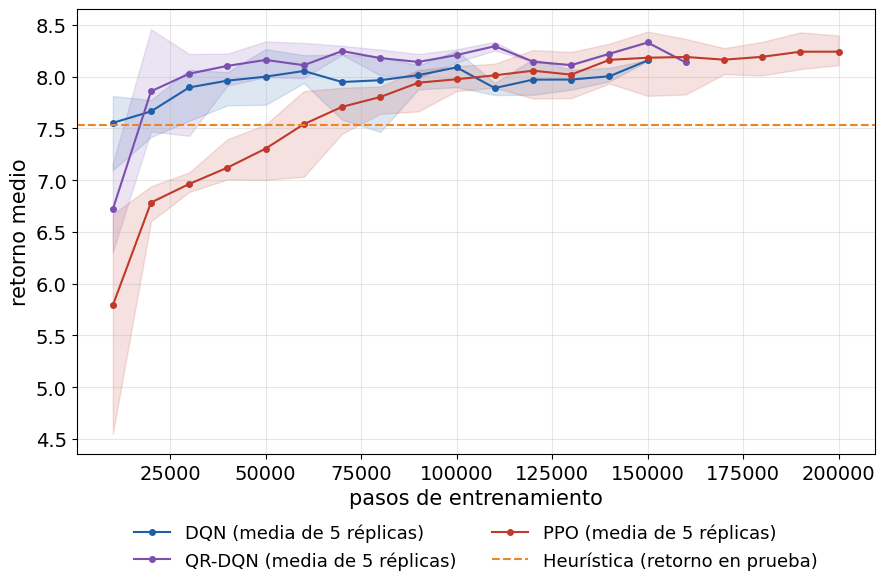

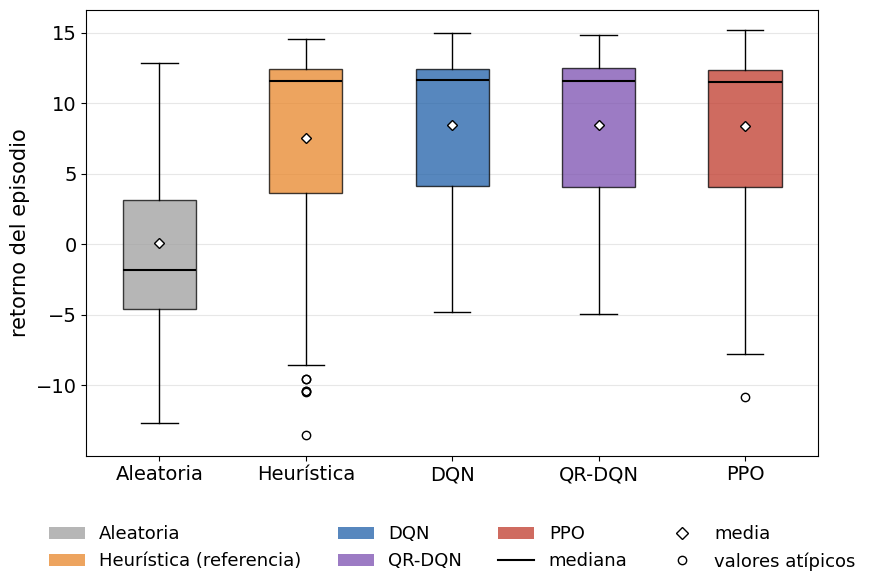

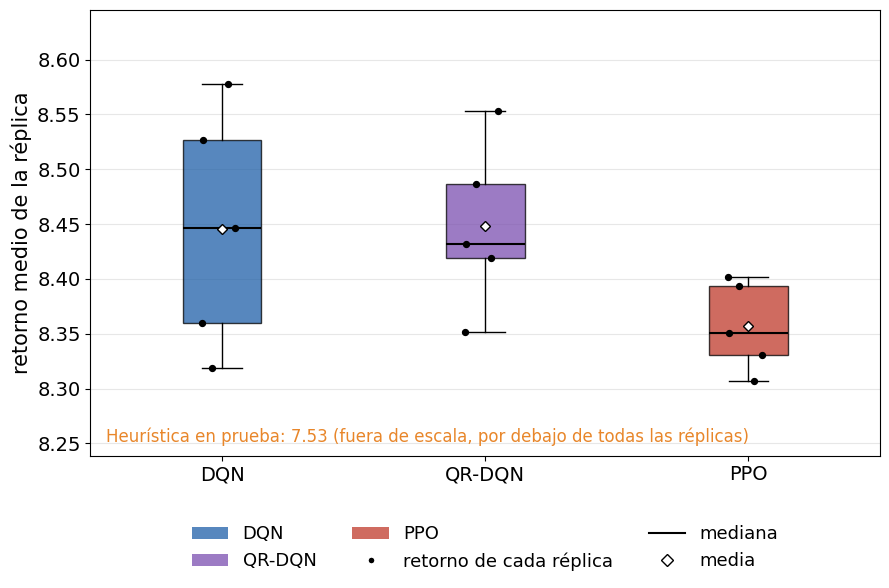

Figuras del artículo guardadas en /content/drive/MyDrive/Proyecto de investigacion/DatosBatsuv2/resultados


In [11]:
# Figuras para el artículo: paneles originales, sin título interno, leyenda completa debajo del gráfico
import matplotlib.pyplot as plt

def figura_articulo(fn, nombre_archivo, columnas=3):
    f, a = plt.subplots(figsize=(9, 6))
    fn(a)
    a.set_title('')                                   # el pie de figura va en LaTeX, no dentro de la imagen
    a.tick_params(labelsize=14)
    a.xaxis.label.set_size(15); a.yaxis.label.set_size(15)
    leg = a.get_legend()
    if leg is not None:
        handles = getattr(leg, 'legend_handles', None) or leg.legendHandles
        labels = [t.get_text() for t in leg.get_texts()]
        a.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=columnas, frameon=False, fontsize=13)
    for t in a.texts: t.set_fontsize(12)              # nota de la heurística en el panel d
    f.tight_layout()
    f.savefig(RESULTADOS_DIR / nombre_archivo, dpi=200, bbox_inches='tight')
    plt.show(); plt.close(f)

figura_articulo(panel_a, 'fig4_algoritmos_aprendizaje.png', columnas=2)
figura_articulo(panel_c, 'fig5_algoritmos_boxplot_episodios.png', columnas=4)
figura_articulo(panel_d, 'fig6_algoritmos_boxplot_replicas.png', columnas=3)
print('Figuras del artículo guardadas en', RESULTADOS_DIR)

## 7. Guardado de resultados

Tabla comparativa, historiales de entrenamiento de los tres agentes y registro JSON con hiperparámetros, versiones y métricas.


In [ ]:
import hashlib, platform, os

def sha_archivo(ruta, n=16):
    return hashlib.sha256(open(ruta, 'rb').read()).hexdigest()[:n]

def cpu_modelo():
    try:
        return next(l.split(':', 1)[1].strip() for l in open('/proc/cpuinfo') if l.startswith('model name'))
    except Exception:
        return platform.processor() or 'desconocido'

sufijo = f'agentes_{ETIQUETA_CORPUS}_{modo_juez}'
comparacion.to_csv(RESULTADOS_DIR / f'comparacion_{sufijo}.csv')
por_replica.to_csv(RESULTADOS_DIR / f'comparacion_por_replica_{sufijo}.csv', index=False)
hist.to_csv(RESULTADOS_DIR / f'entrenamiento_{sufijo}.csv', index=False)

registro = {
    'etiqueta_corpus': ETIQUETA_CORPUS, 'modo_recompensa': modo_juez, 'fecha': time.strftime('%Y-%m-%d %H:%M:%S'),
    'huellas': {'corpus_parquet': sha_archivo(RUTA_CORPUS), 'batsu_sim.py': sha_archivo(BASE_DIR / 'batsu_sim.py'),
                'modelo_recompensa': sha_archivo(RESULTADOS_DIR / f'modelo_recompensa_{ETIQUETA_CORPUS}.pt') if modo_juez == 'modelo' else None,
                'prompt_generador': manif.get('generador', {}).get('prompt_sha256'), 'prompt_juez': manif.get('juez', {}).get('prompt_sha256')},
    'hardware': {'cpu': cpu_modelo(), 'nucleos': os.cpu_count(), 'hilos_torch': torch.get_num_threads()},
    'clave_aleatoria': CLAVE_ALEATORIA, 'claves_replicas': CLAVES_REPLICAS,
    'conjuntos': {'seleccion': N_SEL_EPISODIOS, 'prueba': N_TEST_EPISODIOS, 'rng_seleccion': CLAVE_ALEATORIA + 1, 'rng_prueba': CLAVE_ALEATORIA + 2},
    'hiperparametros': {k: {kk: (vv if not isinstance(vv, dict) else str(vv)) for kk, vv in v.items()} for k, v in HIPER.items()},
    'criterio_parada': {'max_pasos': MAX_PASOS, 'eval_cada': EVAL_CADA, 'paciencia': PACIENCIA},
    'replicas': [{'algoritmo': r['algoritmo'], 'replica': r['replica'], 'clave': r['clave'], 'pasos': r['pasos'], 'mejor_paso': r['mejor_paso'],
                  'retorno_seleccion': round(r['mejor_sel'], 3), 'minutos': round(r['minutos'], 1), 'modelo': r['ruta']} for r in replicas.values()],
    'versiones': {'sb3': sb3.__version__, 'sb3_contrib': __import__('sb3_contrib').__version__, 'torch': torch.__version__, 'gymnasium': gym.__version__},
    'comparacion': comparacion.to_dict(orient='index'),
}
json.dump(registro, open(RESULTADOS_DIR / f'registro_{sufijo}.json', 'w', encoding='utf-8'), ensure_ascii=False, indent=2)
print('Guardado en', RESULTADOS_DIR.name, ':', sorted(p.name for p in RESULTADOS_DIR.iterdir() if sufijo in p.name))
print('Huellas:', registro['huellas']); print('Hardware:', registro['hardware'])


Guardado en resultados : ['comparacion_agentes_v0_escala05_prior40_modelo.csv', 'comparacion_agentes_v0_escala05_prior40_modelo.png', 'comparacion_por_replica_agentes_v0_escala05_prior40_modelo.csv', 'entrenamiento_agentes_v0_escala05_prior40_modelo.csv', 'registro_agentes_v0_escala05_prior40_modelo.json']
Huellas: {'corpus_parquet': 'a9726d610740d384', 'batsu_sim.py': 'fc6d641ae8fc167c', 'modelo_recompensa': 'f804e565bb36d5ba', 'prompt_generador': '6cb6529860c93993', 'prompt_juez': '1dcf58b9ba383117'}
Hardware: {'cpu': 'Intel(R) Xeon(R) CPU @ 2.20GHz', 'nucleos': 2, 'hilos_torch': 1}
